## Selecting Encoders

In [ ]:
conv_topic_idx = 0

topic = conv_topics[conv_topic_idx]

turn = topic['turn'][7]
turn_id = turn['number']
utterance = turn['raw_utterance']
print(utterance)


result = lmd.retrieve_fun(opensearch,utterance,200)

In [ ]:
top_doc = result.iloc[0]
top_doc_body = opensearch.get_doc_body(top_doc._id)
print("TOP DOCUMENT:")
print("-" + top_doc_body)

bottom_doc = result.iloc[199]
bottom_doc_body = opensearch.get_doc_body(bottom_doc._id)
print("BOTTOM DOCUMENT:")
print("-" + bottom_doc_body)



## Selecting query, relevant and irrelevant document

## 3

In [8]:
CLS_token = "[CLS]"
SEP_token = "[SEP]"

In [10]:
cross_encoder_model

In [ ]:
#cross_encoder_POS = cross_encoder_tokenizer(f"{utterance} [SEP] {top_doc_body}", truncation=True, padding=True, return_tensors="pt")
#cross_encoder_NEG = cross_encoder_tokenizer(f"{utterance} [SEP] {bottom_doc_body}", truncation=True, padding=True, return_tensors="pt")
cross_encoder_POS = cross_encoder_tokenizer(utterance,top_doc_body, return_tensors='pt', add_special_tokens=True, max_length = 512, padding=True, truncation = True)
cross_encoder_NEG = cross_encoder_tokenizer(utterance,bottom_doc_body, return_tensors='pt', add_special_tokens=True, max_length = 512, padding=True, truncation = True)


In [13]:
dual_encoder_tokenizer = AutoTokenizer.from_pretrained(dual_encoder_path)
dual_encoder_config = AutoConfig.from_pretrained(dual_encoder_path, output_hidden_states=True, output_attentions=True)
dual_encoder_model = AutoModelForSequenceClassification.from_pretrained(dual_encoder_path, config=dual_encoder_config)

In [14]:
dual_encoder_model

In [15]:
query_embedding = dual_encoder.encode(utterance, convert_to_tensor=True)
relevant_embedding = dual_encoder.encode(top_doc_body, convert_to_tensor=True)
unrelevant_embedding = dual_encoder.encode(bottom_doc_body, convert_to_tensor=True)

In [ ]:
from torch.nn.functional import cosine_similarity

# Compute similarities
positive_similarity = cosine_similarity(query_embedding, relevant_embedding.unsqueeze(0))
negative_similarity = cosine_similarity(query_embedding, unrelevant_embedding.unsqueeze(0))

print("Positive Pair Similarity (Relevant):", positive_similarity.item())
print("Negative Pair Similarity (Non-Relevant):", negative_similarity.item())

## 3

In [ ]:
with torch.no_grad():
    outputs = cross_encoder_model(**cross_encoder_POS)

attention = outputs.attentions
hidden_states = outputs.hidden_states


first_layer_embeddings = hidden_states[0][0]  # Shape: (num_tokens, hidden_dim)
last_layer_embeddings = hidden_states[-1][0]  # Shape: (num_tokens, hidden_dim)


first_10_tokens_first_layer = first_layer_embeddings[:10].detach().numpy()
first_10_tokens_last_layer = last_layer_embeddings[:10].detach().numpy()




In [ ]:
#SIMILARITY

# Determine indices of query and document tokens
sep_token_id = cross_encoder_tokenizer.sep_token_id  # Get the ID of [SEP]
input_ids_POS_list = input_ids_POS[0].tolist()    

query_indices = range(1, input_ids_POS_list.index(sep_token_id))  

# Document tokens are between the first [SEP] and the second [SEP]
doc_indices = range(input_ids_POS_list.index(sep_token_id) + 1, len(input_ids_POS_list) - 1)

from sklearn.metrics.pairwise import cosine_similarity
#import numpy as np

similarities = []

for layer in range(len(hidden_states)):
    layer_embeddings = hidden_states[layer][0].detach().numpy()
    query_embeddings = layer_embeddings[query_indices]
    doc_embeddings = layer_embeddings[doc_indices]

    # Compute similarity matrix
    similarity_matrix = cosine_similarity(query_embeddings, doc_embeddings)
    similarities.append(similarity_matrix)


import matplotlib.pyplot as plt
import numpy as np

# Assuming similarities is a list of similarity matrices (one for each layer)
rows, cols = 3, 4  # Adjust based on the number of layers
fig, ax_full = plt.subplots(rows, cols, figsize=(20, 15))

layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(similarities):  # Avoid indexing beyond available layers
            break
        
        ax = ax_full[r, c]
        similarity_matrix = similarities[layer]
        
        # Plot similarity matrix using matshow (alternative to heatmap)
        cax = ax.matshow(similarity_matrix, cmap="viridis", aspect='auto', vmin=0, vmax=1)

        ax.set_title(f"Query vs Document Similarity - Layer {layer}")
        ax.set_xlabel("Document Tokens")
        ax.set_ylabel("Query Tokens")
        
        # Add colorbar to the side
        fig.colorbar(cax, ax=ax)

        layer += 1

plt.suptitle("Query vs Document Similarities Across Layers", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
print(cross_encoder_tokenizer.decode(cross_encoder_POS["input_ids"][0]))
input_ids_POS = cross_encoder_POS['input_ids']
input_ids_POS_list = input_ids_POS[0].tolist()
input_tokens_POS_list = cross_encoder_tokenizer.convert_ids_to_tokens(input_ids_POS_list)
print(input_tokens_POS_list)

In [ ]:
res_POS = "\n".join("{} \t {}".format(x, y) for x, y in zip(input_ids_POS_list, input_tokens_POS_list))
print(res_POS)

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

layer = 1

rows = 3
cols = 4
fig, ax_full = plt.subplots(rows, cols)
fig.set_figheight(rows*4)
fig.set_figwidth(cols*4+3)
plt.rcParams.update({'font.size': 6})


layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(hidden_states): 
            break
       
        ax = ax_full[r,c]
        
        plt.rcParams.update({'font.size': 10})
        current_hidden_state = hidden_states[layer][0].detach().numpy()

        current_hidden_state = current_hidden_state[:10]
        
        if current_hidden_state.shape[1] == 2:
            twodim = current_hidden_state
        else:
            twodim = PCA().fit_transform(current_hidden_state)[:,:2]

        plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
        im = ax.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
        for word, (x,y) in zip(input_tokens_POS_list, twodim):
            ax.text(x+0.05, y+0.05, word[1:])
        
        # Show all ticks and label them with the respective list entries
        ax.set_title("Layer " + str(layer))
            
        # Loop over data dimensions and create text annotations.
        layer = layer + 1

fig.suptitle("Visualization of all output embeddings from all layers")
plt.show()

In [ ]:
first_layer_embeddings = hidden_states[0][0]  # Shape: (num_tokens, hidden_dim)
last_layer_embeddings = hidden_states[-1][0]  # Shape: (num_tokens, hidden_dim)

# Select first 10 token embeddings
first_10_tokens_first_layer = first_layer_embeddings[:10].detach().numpy()
first_10_tokens_last_layer = last_layer_embeddings[:10].detach().numpy()

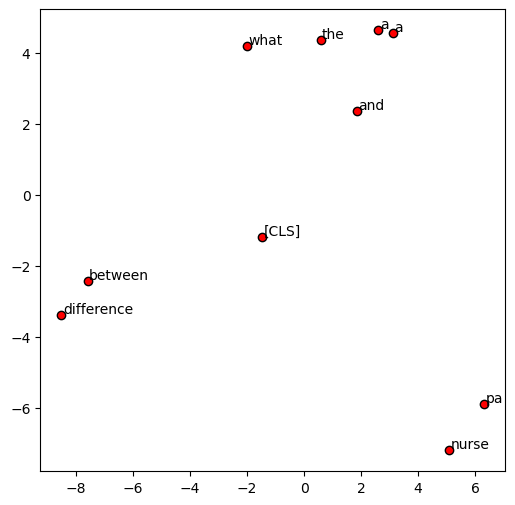

In [ ]:
#Plot the token embeddings of the first-layer  
display_scatterplot(first_10_tokens_first_layer, input_tokens_POS_list[:10])

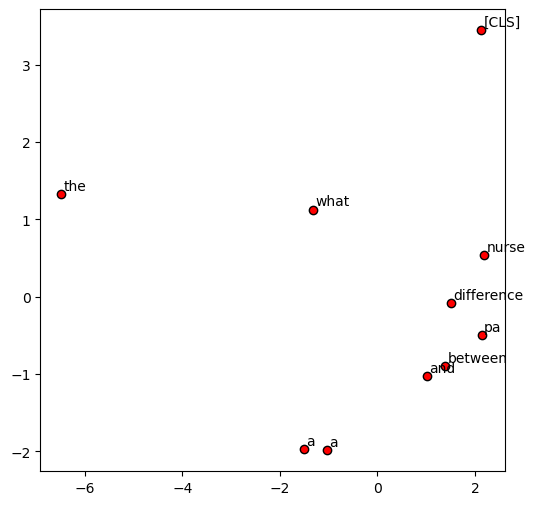

In [ ]:
#Plot the token embeddings of the last-layer 
display_scatterplot(first_10_tokens_last_layer, input_tokens_POS_list[:10])

In [ ]:
def display_scatterplot(data, words):

    if data.shape[1] == 2:
        twodim = data
    else:
        pca = PCA()
        pca.fit(data)
        twodim = pca.transform(data)[:,:2]
    
    plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
    plt.figure(figsize=(6,6))
    plt.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
    for word, (x,y) in zip(words, twodim):
        plt.text(x+0.05, y+0.05, word)

    return

In [42]:
first_layer_embeddings = outputs.hidden_states[0][0][:10].detach().numpy()

display_scatterplot(first_layer_embeddings, input_tokens_POS_list[:10])


In [41]:
for layer_idx, layber_embedding in enumerate(outputs.hidden_states):
    layber_embeddings_10 = layber_embedding[0][:10].detach().numpy()
    display_scatterplot(layber_embeddings_10, input_tokens_POS_list[:10])
    